# SGLT2 training and AC regularization

**Kind:** experiment.

Prepare the fixed SGLT2 population, build atom representations, then train R or U.
The selected architecture, folds, gradient scales and objective coefficients are preserved.
R enables the four AC constraints; U is the unregularized control.

**Executed record.** [Editable source](../../01_training.ipynb). Local paths are displayed relative to the repository root; numerical outputs and figures are unchanged.


In [1]:
LOCAL_PROJECT_ROOT = "."
CONFIG_PATH = "configs/sglt2_R.json"
CHECKPOINT_PATH = "checkpoints/chemeleon_mp.pt"
DEVICE = "cpu"
RUN_MODE = "train"


In [2]:
# Parameters
CONFIG_PATH = "configs/sglt2_U.json"


In [3]:
from pathlib import Path
import os
import sys
import json
from IPython.display import display

# Use the declared repository root in both Colab and local execution.
try:
    import google.colab
except ModuleNotFoundError as exc:
    if exc.name not in {"google", "google.colab"}:
        raise
    IS_COLAB = False
else:
    IS_COLAB = True
ROOT = Path(os.environ.get("XAI_CHEM_ROOT", LOCAL_PROJECT_ROOT)).expanduser().resolve()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print({"runtime": "colab" if IS_COLAB else "local", "root": str(ROOT), "python": sys.executable})

# Numerical tables, chemistry figures, and explicit CPU execution.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)
%matplotlib inline


{'runtime': 'local', 'root': '.', 'python': 'python'}


Matplotlib is building the font cache; this may take a moment.


## Fixed inputs and folds

In [4]:
import gzip
import shutil

run_root = ROOT / "notebooks_for_sglt2/output/sglt2"
run_root.mkdir(parents=True, exist_ok=True)
dataset_path = ROOT / "sglt2_data/sglt2.csv"
fold_path = ROOT / "sglt2_data/sglt2_folds.csv"
mmp_path = run_root / "training_mmp.csv"
with gzip.open(ROOT / "sglt2_data/sglt2_training_mmp.csv.gz", "rb") as src, mmp_path.open("wb") as dst:
    shutil.copyfileobj(src, dst)
dataset = pd.read_csv(dataset_path)
folds = pd.read_csv(fold_path)
display(dataset[["index", "cid", "Smiles", "pIC50"]].head())
print({"molecules": len(dataset), "fold_counts": folds["fold"].value_counts().sort_index().to_dict()})


,index,cid,Smiles,pIC50
0,1,sglt2_0001,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,9.522879
1,2,sglt2_0002,OC[C@H]1O[C@]2(OCc3cc(Cl)c(Cc4ccc(OC(F)(F)F)cc...,9.522879
2,3,sglt2_0003,CCOc1ccc(Cc2cc([C@@H]3O[C@H](SC)[C@@H](O)[C@H]...,9.511449
3,4,sglt2_0004,CCc1ccc(Cc2cc([C@@H]3O[C@H](CO)C(F)(F)[C@H](O)...,9.455932
4,5,sglt2_0005,OC[C@H]1O[C@@H](c2cc(Cc3ccc(C4CC4)cc3)c(Cl)c3c...,9.434152


{'molecules': 1259, 'fold_counts': {0: 254, 1: 253, 2: 251, 3: 251, 4: 250}}


### Confirm the activity-balanced split

In [5]:
from xai_chem.graphs import assign_activity_balanced_folds

rebuilt_folds = assign_activity_balanced_folds(dataset, n_folds=5, n_bins=5, seed=42)
# A scientific acceptance check, not a replacement split.
pd.testing.assert_frame_equal(
    rebuilt_folds[["index", "fold"]].reset_index(drop=True),
    folds[["index", "fold"]].reset_index(drop=True),
    check_dtype=False,
)
display(folds.groupby("fold")["pIC50"].agg(["count", "mean", "std"]))


,count,mean,std
fold,,,
0,254,7.570852,1.154360
1,253,7.532561,1.206085
2,251,7.606328,1.175921
3,251,7.581891,1.129996
4,250,7.608022,1.133272


## Graphs and atom mapping

{'run_graph_build': True, 'graph_root': 'notebooks_for_sglt2/output/sglt2/graphs'}


,graph_atom_index,atomic_number,smiles_to_graph_atom_index
0,0,6,0
1,1,6,1
2,2,6,2
3,3,8,3
4,4,6,4
5,5,6,5
6,6,6,6
7,7,6,7
8,8,17,8
9,9,6,9


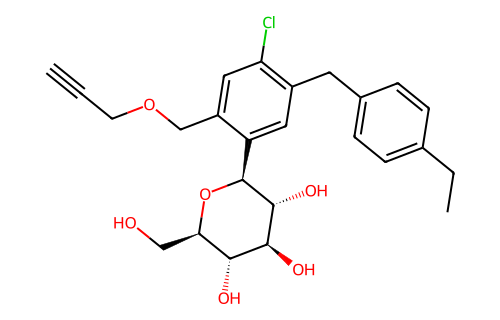

{'graph_nodes': 32, 'directed_edges': 68, 'bond_feature_shape': (68, 6), 'node_features_before_encoder': (32, 0)}


In [6]:
from xai_chem.graphs import build_graphs
from xai_chem.io import load_pyg_data
from rdkit import Chem
from rdkit.Chem import Draw

graph_root = run_root / "graphs"
RUN_GRAPH_BUILD = not graph_root.exists()
print({"run_graph_build": RUN_GRAPH_BUILD, "graph_root": str(graph_root)})
if RUN_GRAPH_BUILD:
    build_graphs(dataset_path, graph_root)

graph = load_pyg_data(graph_root / "graph_0001.pt")
display(pd.DataFrame({
    "graph_atom_index": np.arange(graph.num_nodes),
    "atomic_number": graph.atomic_numbers.numpy(),
    "smiles_to_graph_atom_index": graph.smiles_to_graph_atom_index.numpy(),
}))
display(Draw.MolToImage(Chem.MolFromSmiles(dataset.iloc[0]["Smiles"]), size=(500, 320)))
print({"graph_nodes": graph.num_nodes, "directed_edges": graph.num_edges,
       "bond_feature_shape": tuple(graph.edge_attr.shape), "node_features_before_encoder": tuple(graph.x.shape)})


## Train-only fragment frequencies

In [7]:
from xai_chem.brics import (
    load_graph_fragment_inputs, build_brics_cache_payload,
    write_or_reuse_brics_cache, fragment_summary_frame,
)

items = load_graph_fragment_inputs(dataset_path, graph_root)
cache_root = run_root / "brics"
structure_payload = build_brics_cache_payload(items, min_heavy_atoms=1, min_count=3)
print(write_or_reuse_brics_cache(structure_payload, cache_root / "structure.pkl"))
display(fragment_summary_frame(structure_payload, len(items)).head(12))


written


,fragment,molecule_count,occurrence_count,frequency,n_molecules
0,[3*]O[H],1194,4716,0.948372,1259
1,[8*]C([8*])([H])[H],1120,1129,0.889595,1259
2,[4*]C([8*])([H])[H],1012,1073,0.803813,1259
3,[13*][C@]1([H])O[C@@]([13*])([H])[C@]([15*])([...,906,906,0.719619,1259
4,[16*]c1c([H])c([H])c([16*])c([H])c1[H],636,638,0.505163,1259
5,[3*]O[3*],461,522,0.366164,1259
6,[16*]c1c([H])c([16*])c(Cl)c([H])c1[H],377,377,0.299444,1259
7,[8*]C([H])([H])[H],300,333,0.238284,1259
8,[3*]OC([H])([H])[H],201,244,0.159651,1259
9,[4*]C([H])([H])C([H])([H])[H],179,184,0.142176,1259


In [8]:
cache_audit = []
for fold in range(5):
    train_rows = set(folds.index[folds["fold"].ne(fold)])
    train_items = tuple(item for item in items if item.source_row in train_rows)
    payload = build_brics_cache_payload(
        train_items, min_heavy_atoms=1, min_count=3,
        activity_values=[item.pIC50 for item in train_items],
    )
    status = write_or_reuse_brics_cache(payload, cache_root / f"fold_{fold}_train.pkl")
    cache_audit.append({"validation_fold": fold, "training_molecules": len(train_items),
                        "fragments": len(payload["global_frag_freqs"]),
                        "positive_margin": payload["positive_margin"], "status": status})
display(pd.DataFrame(cache_audit))

output = run_root / "csv"
output.mkdir(parents=True, exist_ok=True)
pd.DataFrame(cache_audit).to_csv(output / "brics_preparation.csv", index=False)


,validation_fold,training_molecules,fragments,positive_margin,status
0,0,1005,175,0.023908,written
1,1,1006,170,0.024237,written
2,2,1008,176,0.023288,written
3,3,1008,172,0.024525,written
4,4,1009,173,0.024585,written


{'selected_pairs': 23029, 'molecules': 1259, 'atoms': 39530}


,pair_id,document_id,i_id,j_id,mmp_class,dy
0,0,CHEMBL1139015,672,922,single_cut,0.702574
1,1,CHEMBL1139015,672,971,single_cut,0.831976
2,2,CHEMBL1139015,672,995,single_cut,0.922985
3,3,CHEMBL1139015,672,996,single_cut,0.925140
4,4,CHEMBL1139015,922,971,single_cut,0.129402


mmp_class
double_cut    15965
single_cut     7064
Name: count, dtype: int64

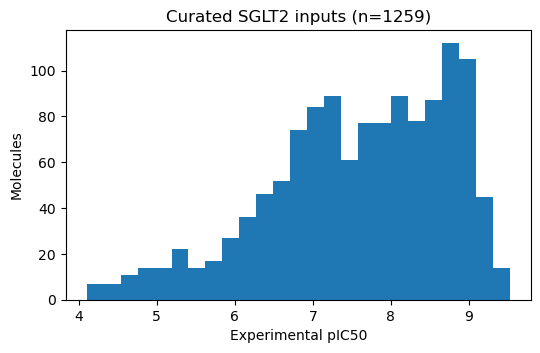

In [9]:
mmp = pd.read_csv(mmp_path)
print({"selected_pairs": len(mmp), "molecules": len(items),
       "atoms": sum(item.num_nodes for item in items)})
display(mmp[["pair_id", "document_id", "i_id", "j_id", "mmp_class", "dy"]].head())
display(mmp["mmp_class"].value_counts())
figure, axis = plt.subplots(figsize=(6, 3.5))
axis.hist(dataset["pIC50"], bins=25)
axis.set(xlabel="Experimental pIC50", ylabel="Molecules", title=f"Curated SGLT2 inputs (n={len(dataset)})")
display(figure)
plt.close(figure)


## Singleton CheMeleon representations

Use the official encoder checkpoint. Each molecule is encoded separately.

In [10]:
from xai_chem.representations import load_molecule_inputs_with_provenance

loaded = load_molecule_inputs_with_provenance(
    dataset_path,
    graph_root,
    dataset_id="sglt2_inhibitors_processed_chembl3884_260729",
)
print({"molecules": len(loaded.molecules), "excluded": len(loaded.exclusions)})
display(pd.DataFrame([{"graph_idx": molecule.graph_idx, "smiles": molecule.smiles,
                       "atom_count": len(molecule.atomic_numbers)}
                      for molecule in loaded.molecules[:3]]))

{'molecules': 1259, 'excluded': 0}


,graph_idx,smiles,atom_count
0,0,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,32
1,1,OC[C@H]1O[C@]2(OCc3cc(Cl)c(Cc4ccc(OC(F)(F)F)cc...,32
2,2,CCOc1ccc(Cc2cc([C@@H]3O[C@H](SC)[C@@H](O)[C@H]...,30


In [11]:
from xai_chem.representations import CheMeleonSingletonProvider
from xai_chem.chemistry import validate_representation_mapping

provider = CheMeleonSingletonProvider(checkpoint_path=ROOT / CHECKPOINT_PATH, device=DEVICE)
sample = loaded.molecules[0]
representation = provider.extract_one(sample)
validate_representation_mapping(sample, representation)
print({"raw_shape": representation.values.shape, "singleton": True, "dtype": str(representation.values.dtype)})
display(pd.DataFrame({"graph_atom_index": representation.graph_atom_index,
                       "atomic_number": representation.atomic_numbers,
                       "raw_feature_0": representation.values[:, 0]}).head(20))

{'raw_shape': (32, 2048), 'singleton': True, 'dtype': 'float32'}


,graph_atom_index,atomic_number,raw_feature_0
0,0,6,0.000000
1,1,6,0.000000
2,2,6,0.278708
3,3,8,0.000000
4,4,6,0.325792
5,5,6,0.000000
6,6,6,0.418995
7,7,6,0.000000
8,8,17,0.000000
9,9,6,0.000000


In [12]:
from xai_chem.representations import build_or_reuse_cache

bundle = build_or_reuse_cache(
    run_root / "representations", provider, loaded.molecules,
    input_provenance=loaded.input_provenance, provider_scoped_root=True,
)
print({"cache": str(bundle.root), "molecules": len(bundle.molecule_rows),
       "atoms": len(bundle.atomic_numbers), "dimension": bundle.values.shape[1]})
display(pd.DataFrame(bundle.molecule_rows).drop(columns="provider_metadata").head())

{'cache': 'notebooks_for_sglt2/output/sglt2/representations', 'molecules': 1259, 'atoms': 39530, 'dimension': 2048}


,graph_idx,n_atoms,offset_start,offset_stop,sample_id,smiles
0,0,32,0,32,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...
1,1,32,32,64,2,OC[C@H]1O[C@]2(OCc3cc(Cl)c(Cc4ccc(OC(F)(F)F)cc...
2,2,30,64,94,3,CCOc1ccc(Cc2cc([C@@H]3O[C@H](SC)[C@@H](O)[C@H]...
3,3,28,94,122,4,CCc1ccc(Cc2cc([C@@H]3O[C@H](CO)C(F)(F)[C@H](O)...
4,4,31,122,153,5,OC[C@H]1O[C@@H](c2cc(Cc3ccc(C4CC4)cc3)c(Cl)c3c...


## Model and objective

The JSON contains the selected paper settings. Fold-specific gradient scales are fixed,
not recalibrated. Label scaling and fragment frequencies use training rows only.

$$
L=L_{\mathrm{pred}}+\lambda_m L_{\mathrm{MMP}}+\lambda_f L_{\mathrm{frag}}
$$

$$
L_{\mathrm{MMP}}=\frac{w_c s_c L_{\mathrm{core}}+w_d s_d L_{\mathrm{diff}}}{w_c+w_d},\qquad L_{\mathrm{frag}}=w_p s_p L_{\mathrm{pos}}+w_v s_v L_{\mathrm{cons}}
$$

The outer weights are `mmp_weight` and `fragment_frequency_weight`; component weights and fixed gradient scales are displayed below.


In [13]:
from xai_chem.dataset import DataConfig, CacheBackedGraphDataset
from xai_chem.config import TrainingConfig, LossGradientScaling, CHECKED_CHEMBL3884_260729_FOLD_CONTRACTS, MMP_CORE_MAPPING_METHOD
from xai_chem.training import run_fold_training
from xai_chem.results import load_completed_fold_results, check_additivity, assert_completed_result_matches_config
from xai_chem.transfer import measure_ac_constraints

settings = json.loads((ROOT / CONFIG_PATH).read_text())
condition = Path(CONFIG_PATH).stem.removeprefix("sglt2_")
fold_numbers = settings.pop("folds")
gradient_settings = settings.pop("loss_gradient_scaling")
data_config = DataConfig(dataset_csv=dataset_path, graph_root=graph_root, fold_csv=fold_path,
                         representation_cache=run_root / "representations",
                         graph_file_template="graph_{molecule_id:04d}.pt")
raw_dataset = CacheBackedGraphDataset(data_config, validate_all=True)
configs = {}
for fold in fold_numbers:
    expected = CHECKED_CHEMBL3884_260729_FOLD_CONTRACTS[fold]
    record = gradient_settings["by_fold"].get(str(fold), gradient_settings["default"])
    configs[fold] = TrainingConfig(
        data=data_config, mmp_csv=mmp_path, fragment_cache=cache_root / f"fold_{fold}_train.pkl",
        output_dir=run_root / condition / f"fold_{fold}", device=DEVICE, validation_fold=fold,
        run_profile="strict_lightweight", mmp_pair_batch_size=128, scaling_mode="standard",
        mmp_huber_beta=0.25, fragment_min_heavy_atoms=1, fragment_min_count=3,
        fragment_min_frequency=0.1, heads=4, use_edge_features=True, atom_bias=True,
        loss_gradient_scaling=LossGradientScaling(**record),
        expected_explicit_hydrogen_exclusions=0, expected_mmp_pairs_excluded_by_hydrogen=0,
        expected_input_exclusions=0, expected_mmp_pairs_excluded_by_input=0,
        expected_mmp_source_pairs=23029, expected_mmp_symmetry_ambiguous_pairs=4845,
        expected_mmp_max_automorphism_candidates=16, expected_mmp_core_mapping_method=MMP_CORE_MAPPING_METHOD,
        **expected, **settings,
    )
display(pd.DataFrame([{"fold": fold, **config.as_dict()} for fold, config in configs.items()]).T)


,0,1,2,3,4
fold,0,1,2,3,4
data,"{'dataset_csv': 'sglt2_data/sglt2.csv', 'graph...","{'dataset_csv': 'sglt2_data/sglt2.csv', 'graph...","{'dataset_csv': 'sglt2_data/sglt2.csv', 'graph...","{'dataset_csv': 'sglt2_data/sglt2.csv', 'graph...","{'dataset_csv': 'sglt2_data/sglt2.csv', 'graph..."
mmp_csv,notebooks_for_sglt2/output/sglt2/training_mmp.csv,notebooks_for_sglt2/output/sglt2/training_mmp.csv,notebooks_for_sglt2/output/sglt2/training_mmp.csv,notebooks_for_sglt2/output/sglt2/training_mmp.csv,notebooks_for_sglt2/output/sglt2/training_mmp.csv
output_dir,notebooks_for_sglt2/output/sglt2/U/fold_0,notebooks_for_sglt2/output/sglt2/U/fold_1,notebooks_for_sglt2/output/sglt2/U/fold_2,notebooks_for_sglt2/output/sglt2/U/fold_3,notebooks_for_sglt2/output/sglt2/U/fold_4
device,cpu,cpu,cpu,cpu,cpu
fragment_cache,notebooks_for_sglt2/output/sglt2/brics/fold_0_...,notebooks_for_sglt2/output/sglt2/brics/fold_1_...,notebooks_for_sglt2/output/sglt2/brics/fold_2_...,notebooks_for_sglt2/output/sglt2/brics/fold_3_...,notebooks_for_sglt2/output/sglt2/brics/fold_4_...
run_profile,strict_lightweight,strict_lightweight,strict_lightweight,strict_lightweight,strict_lightweight
training_scope,cross_validation_fold,cross_validation_fold,cross_validation_fold,cross_validation_fold,cross_validation_fold
optimization_mode,minibatch,minibatch,minibatch,minibatch,minibatch
checkpoint_selection,best_validation,best_validation,best_validation,best_validation,best_validation


## Training and raw atom contributions

In [14]:
def print_progress(row):
    if int(row["epoch"]) == 1 or int(row["epoch"]) % 20 == 0:
        print({key: row[key] for key in ("epoch", "optimization_total", "training_rmse_raw", "validation_rmse_raw")}, flush=True)

completed = {}
for fold, config in configs.items():
    config.output_dir.parent.mkdir(parents=True, exist_ok=True)
    if RUN_MODE == "train":
        run_fold_training(config, raw_dataset=raw_dataset, epoch_observer=print_progress)
    elif RUN_MODE != "reuse":
        raise ValueError("RUN_MODE must be train or reuse")
    completed[fold] = load_completed_fold_results(config.output_dir)
    assert_completed_result_matches_config(completed[fold], config)
    display(completed[fold].history.iloc[[0, -1]])
    display(check_additivity(completed[fold].predictions, completed[fold].atom_contributions))


{'epoch': 1, 'optimization_total': 0.2966148570402345, 'training_rmse_raw': 1.1522638325538586, 'validation_rmse_raw': 1.1479420533924076}


{'epoch': 20, 'optimization_total': 0.04344900645204444, 'training_rmse_raw': 0.34002158017603645, 'validation_rmse_raw': 0.5422012063528365}


{'epoch': 40, 'optimization_total': 0.018783389491524864, 'training_rmse_raw': 0.2076817136814282, 'validation_rmse_raw': 0.5484582869891405}


{'epoch': 60, 'optimization_total': 0.010588611250937874, 'training_rmse_raw': 0.1940645978571579, 'validation_rmse_raw': 0.5550064459417803}


,epoch,optimization_prediction_loss_scaled,optimization_prediction_mse_scaled,optimization_mmp_total,optimization_mmp_weighted,optimization_mmp_core,optimization_mmp_difference,optimization_fragment_total,optimization_fragment_weighted,optimization_fragment_positive,...,optimization_fragment_active_occurrences,optimization_total,training_mae_raw,training_rmse_raw,training_r2_raw,validation_mse_scaled,validation_mae_raw,validation_rmse_raw,validation_r2_raw,is_best
0,1,0.296615,0.993246,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.296615,0.931917,1.152264,0.013214,0.979398,0.919463,1.147942,0.007179,True
78,79,0.008881,0.021695,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.008881,0.108845,0.176357,0.976885,0.226987,0.386886,0.552638,0.769902,False


...

{'epoch': 60, 'optimization_total': 0.010500586913793363, 'training_rmse_raw': 0.19800180979585535, 'validation_rmse_raw': 0.5171587126404292}


{'epoch': 80, 'optimization_total': 0.009122676375747554, 'training_rmse_raw': 0.17755230811199874, 'validation_rmse_raw': 0.512443320698998}


{'epoch': 100, 'optimization_total': 0.008125374813603812, 'training_rmse_raw': 0.15727703397994303, 'validation_rmse_raw': 0.5173829772419017}


,epoch,optimization_prediction_loss_scaled,optimization_prediction_mse_scaled,optimization_mmp_total,optimization_mmp_weighted,optimization_mmp_core,optimization_mmp_difference,optimization_fragment_total,optimization_fragment_weighted,optimization_fragment_positive,...,optimization_fragment_active_occurrences,optimization_total,training_mae_raw,training_rmse_raw,training_r2_raw,validation_mse_scaled,validation_mae_raw,validation_rmse_raw,validation_r2_raw,is_best
0,1,0.294567,0.993808,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.294567,0.931391,1.151822,0.022422,0.920562,0.917927,1.117728,0.023336,True
99,100,0.008125,0.020045,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.008125,0.091604,0.157277,0.981773,0.197245,0.371115,0.517383,0.790735,False


,source_row_index,split,n_atoms,atom_sum_scaled_recomputed,additivity_residual_scaled_recomputed,atom_sum_raw_recomputed,additivity_residual_raw_recomputed,scaled_tolerance,raw_tolerance,scaled_pass,raw_pass
0,0,train,32,1.663496,2.782326e-07,1.937901,1.153821e-07,0.000003,0.000020,True,True
1,1,train,32,1.644069,1.401640e-07,1.915269,-1.518056e-07,0.000003,0.000020,True,True
2,2,train,30,1.664592,2.251472e-07,1.939178,4.717149e-07,0.000003,0.000020,True,True
3,3,train,28,1.565598,1.110223e-15,1.823853,-1.834705e-07,0.000003,0.000020,True,True
4,4,train,31,1.612411,7.846393e-08,1.878389,-1.846347e-07,0.000003,0.000020,True,True
...,...,...,...,...,...,...,...,...,...,...,...
1254,1254,validation,36,-2.681836,4.991889e-07,-3.124223,3.091991e-07,0.000004,0.000016,True,True
1255,1255,train,29,-3.013334,1.341104e-07,-3.510403,3.464520e-07,0.000004,0.000016,True,True
1256,1256,train,35,-3.049412,-2.756715e-07,-3.552432,-6.891787e-07,0.000004,0.000016,True,True
1257,1257,train,28,-2.882230,-2.235174e-07,-3.357673,-3.948808e-07,0.000004,0.000016,True,True


## Check prediction quality and AC constraints

Raw ACs sum to the prediction after adding the separate affine baseline.
Constraint values use the same loss definitions on training and validation populations.
Their reduction does not imply improved predictive accuracy or causal atomic effects.


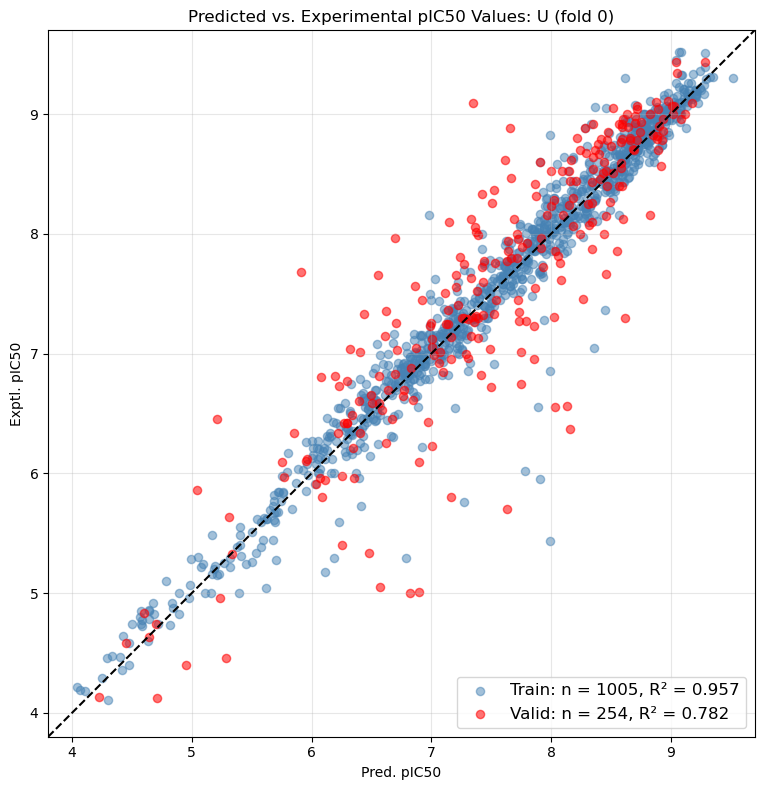

,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,train,1005,0.24050,0.145508,0.957012,0.957522
1,validation,254,0.53768,0.379290,0.782190,0.784148


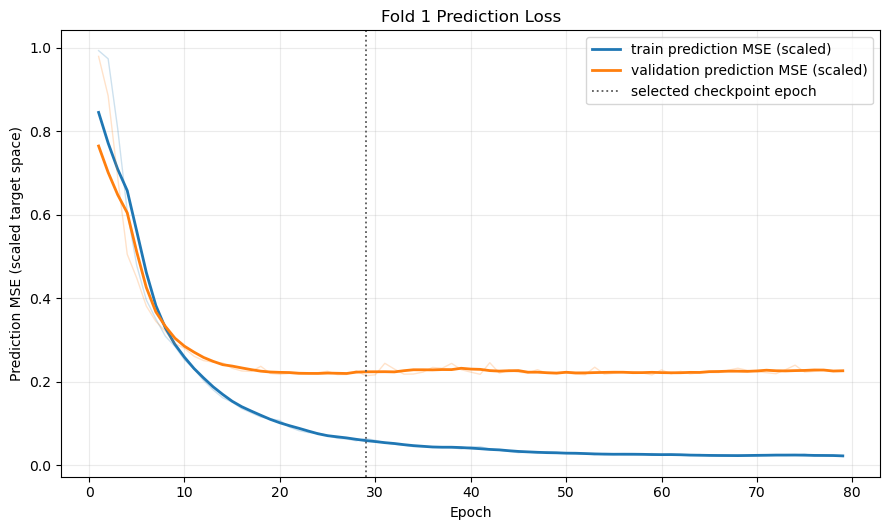

,split,mmp_pairs,core,difference,positive,consistency
0,train,15186,0.001622,0.028529,3.505347,2.212213
1,validation,772,0.001329,0.059135,3.165028,1.976082


,source_row_index,dataset_position,molecule_id,sample_id,smiles,split,graph_atom_index,smiles_atom_index,atomic_number,atom_contribution_scaled,atom_contribution_raw
0,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,0,0,6,0.052354,0.060728
1,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,1,1,6,0.072134,0.083673
2,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,2,2,6,0.113161,0.131261
3,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,3,3,8,0.067618,0.078434
4,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,4,4,6,0.004347,0.005042


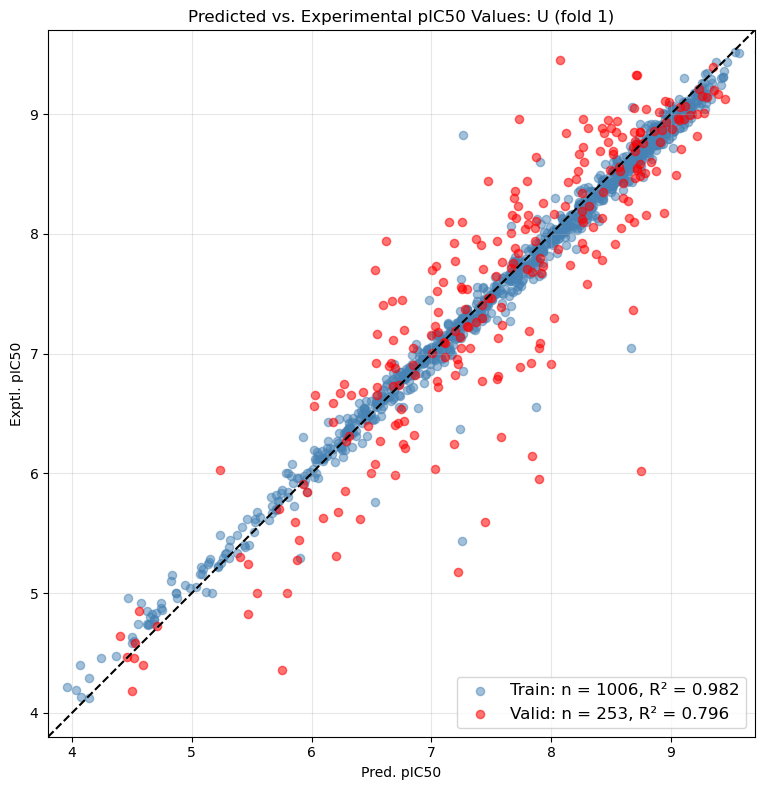

,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,train,1006,0.153442,0.090064,0.982085,0.984856
1,validation,253,0.543265,0.389394,0.796302,0.798933


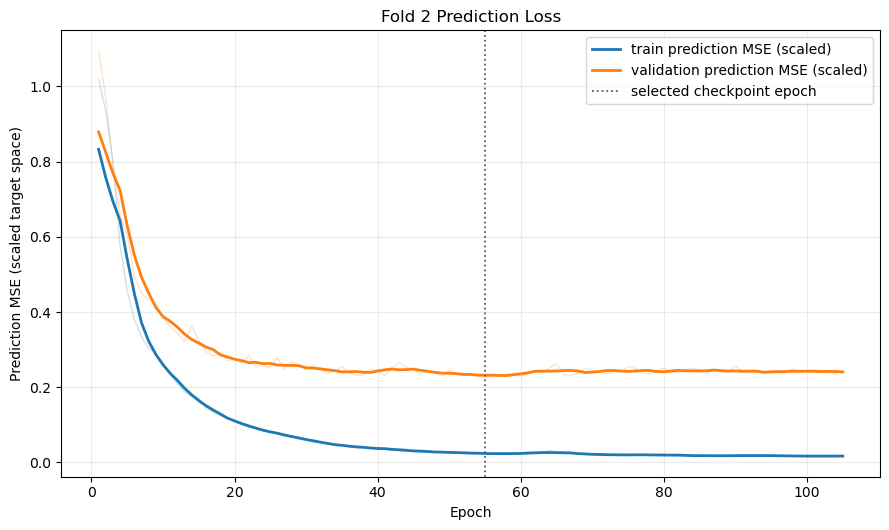

,split,mmp_pairs,core,difference,positive,consistency
0,train,15042,0.001925,0.023974,4.000519,2.565809
1,validation,848,0.001855,0.056331,3.806291,2.392805


,source_row_index,dataset_position,molecule_id,sample_id,smiles,split,graph_atom_index,smiles_atom_index,atomic_number,atom_contribution_scaled,atom_contribution_raw
0,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,0,0,6,0.096099,0.110167
1,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,1,1,6,0.149644,0.171551
2,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,2,2,6,0.222255,0.254792
3,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,3,3,8,0.127044,0.145643
4,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,4,4,6,-0.015007,-0.017204


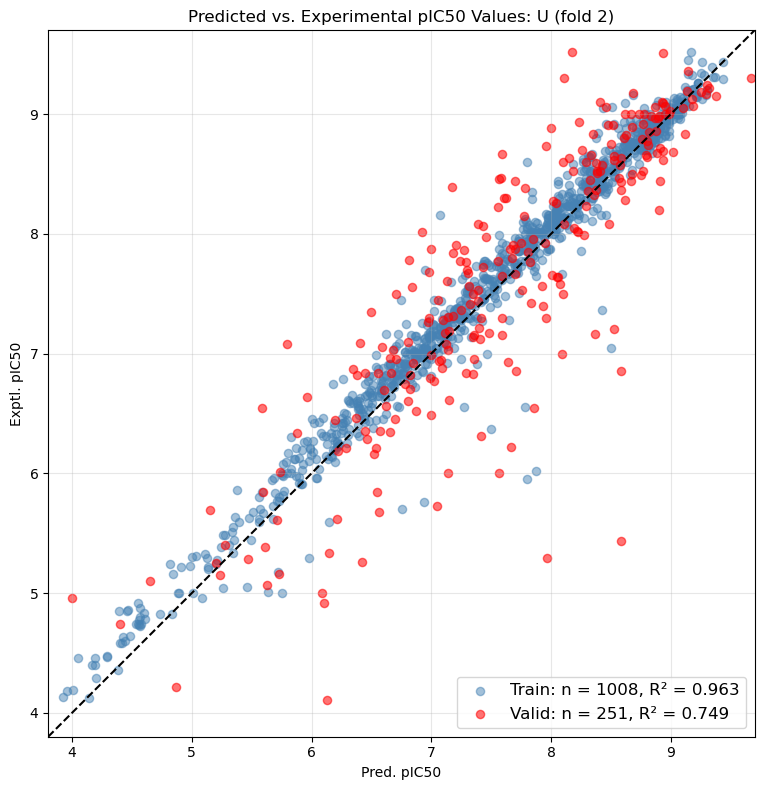

,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,train,1008,0.221953,0.148617,0.963038,0.969574
1,validation,251,0.588059,0.409465,0.748916,0.750450


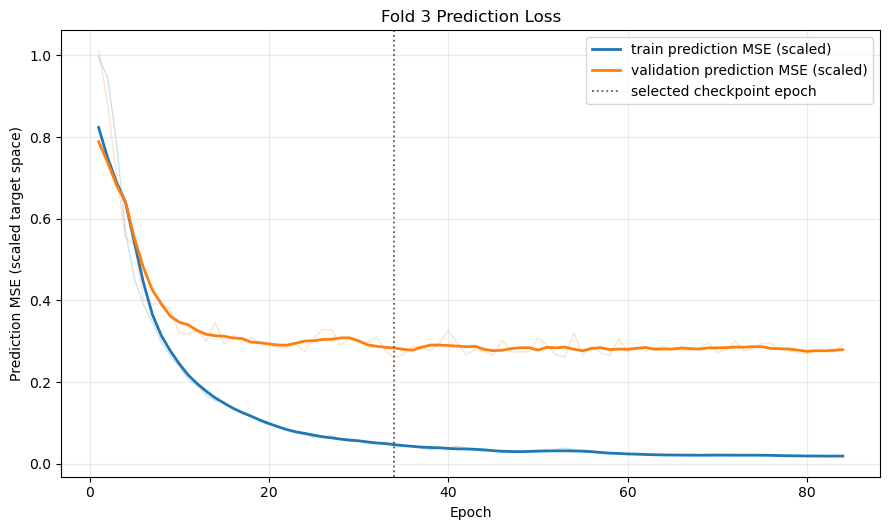

,split,mmp_pairs,core,difference,positive,consistency
0,train,14507,0.001905,0.029975,3.649266,2.329373
1,validation,923,0.001473,0.045933,3.297086,2.110287


,source_row_index,dataset_position,molecule_id,sample_id,smiles,split,graph_atom_index,smiles_atom_index,atomic_number,atom_contribution_scaled,atom_contribution_raw
0,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,validation,0,0,6,-0.048922,-0.056479
1,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,validation,1,1,6,-0.053689,-0.061982
2,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,validation,2,2,6,0.000678,0.000782
3,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,validation,3,3,8,-0.032451,-0.037464
4,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,validation,4,4,6,-0.021915,-0.025300


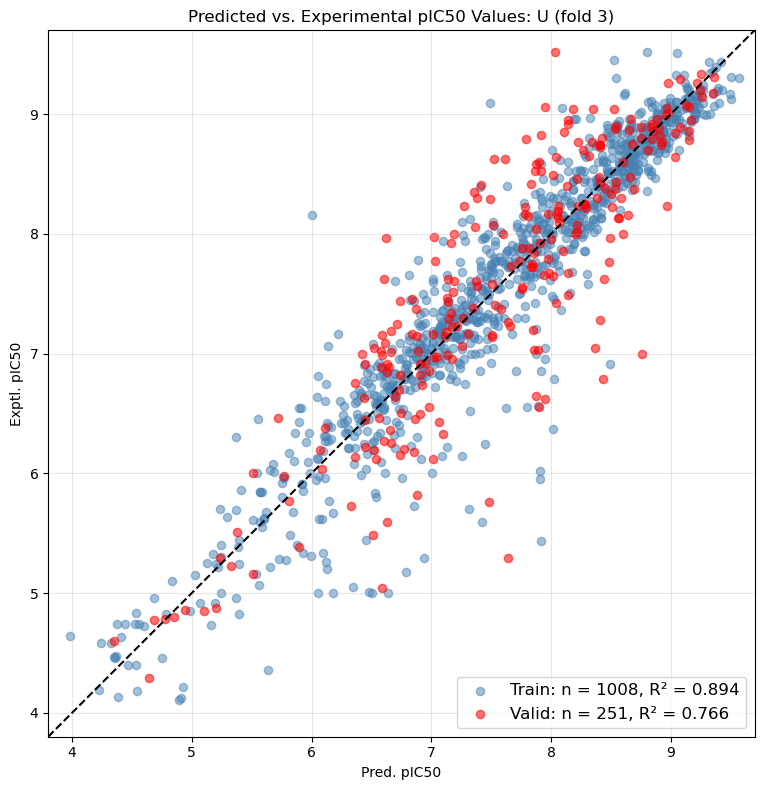

,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,train,1008,0.379343,0.248768,0.894134,0.894655
1,validation,251,0.545701,0.393948,0.765853,0.767321


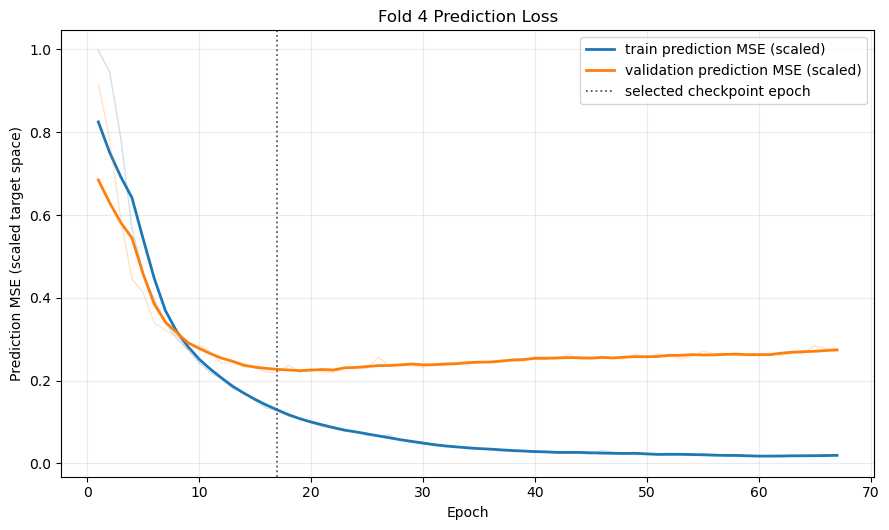

,split,mmp_pairs,core,difference,positive,consistency
0,train,14596,0.001012,0.037786,2.552834,1.525941
1,validation,928,0.000834,0.049361,2.442286,1.368529


,source_row_index,dataset_position,molecule_id,sample_id,smiles,split,graph_atom_index,smiles_atom_index,atomic_number,atom_contribution_scaled,atom_contribution_raw
0,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,0,0,6,0.004313,0.005028
1,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,1,1,6,0.057040,0.066502
2,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,2,2,6,0.088221,0.102855
3,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,3,3,8,0.043019,0.050155
4,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,4,4,6,0.000140,0.000164


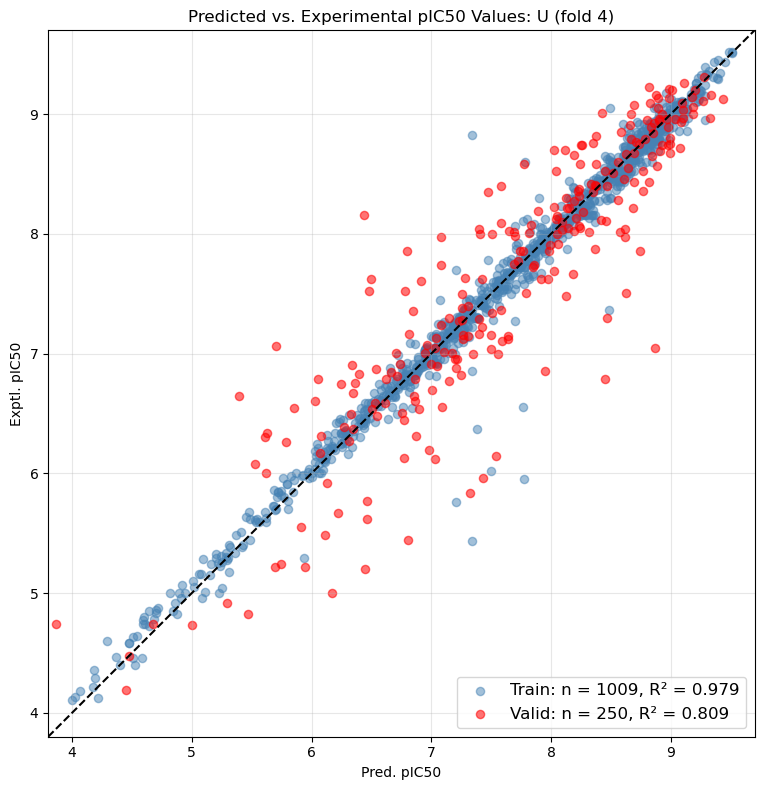

,split,n,rmse_raw,mae_raw,r2_score_raw,pearson_r_squared_raw
0,train,1009,0.167953,0.085864,0.979215,0.979680
1,validation,250,0.494168,0.353760,0.809093,0.814603


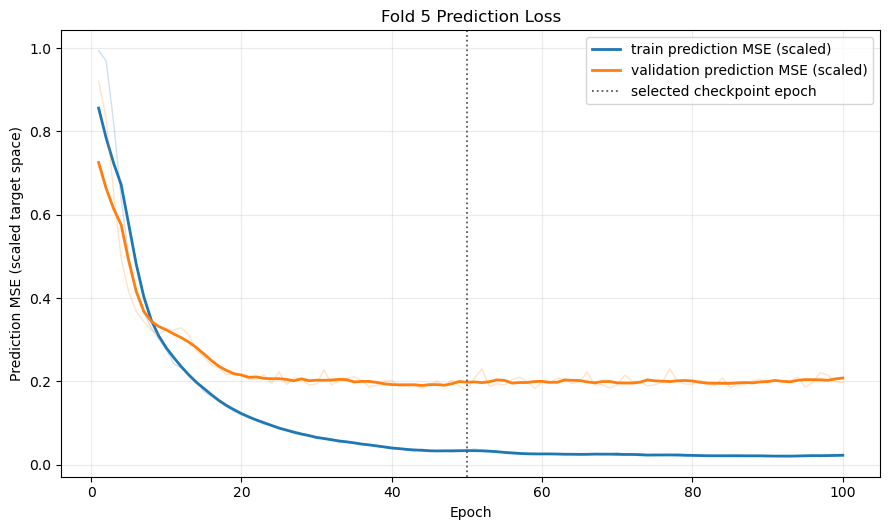

,split,mmp_pairs,core,difference,positive,consistency
0,train,14262,0.001907,0.029041,3.161743,2.343573
1,validation,1035,0.001406,0.036660,2.556224,1.951756


,source_row_index,dataset_position,molecule_id,sample_id,smiles,split,graph_atom_index,smiles_atom_index,atomic_number,atom_contribution_scaled,atom_contribution_raw
0,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,0,0,6,0.102695,0.119636
1,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,1,1,6,0.110064,0.128219
2,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,2,2,6,0.168212,0.195959
3,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,3,3,8,0.098605,0.114871
4,0,0,1,1,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,train,4,4,6,0.011416,0.013300


In [15]:
from xai_chem.plotting import plot_train_validation_yy, plot_prediction_loss_curves, save_publication_figure
for fold, result in completed.items():
    figure, scores = plot_train_validation_yy(result, run_name=condition, limits=(3.8, 9.7))
    save_publication_figure(figure, run_root / "vis" / f"{condition}_fold_{fold}_yy.png")
    display(figure); plt.close(figure)
    display(scores)
    figure = plot_prediction_loss_curves(result)
    save_publication_figure(figure, run_root / "vis" / f"{condition}_fold_{fold}_learning.png")
    display(figure); plt.close(figure)
    display(pd.DataFrame([measure_ac_constraints(result, raw_dataset, mmp_path, split=split)
                          for split in ["train", "validation"]]))
    display(result.atom_contributions.head())


{'raw_ac_limit': 0.2070361226797104, 'scale_scope': 'displayed molecules across configured folds', 'condition': 'U'}


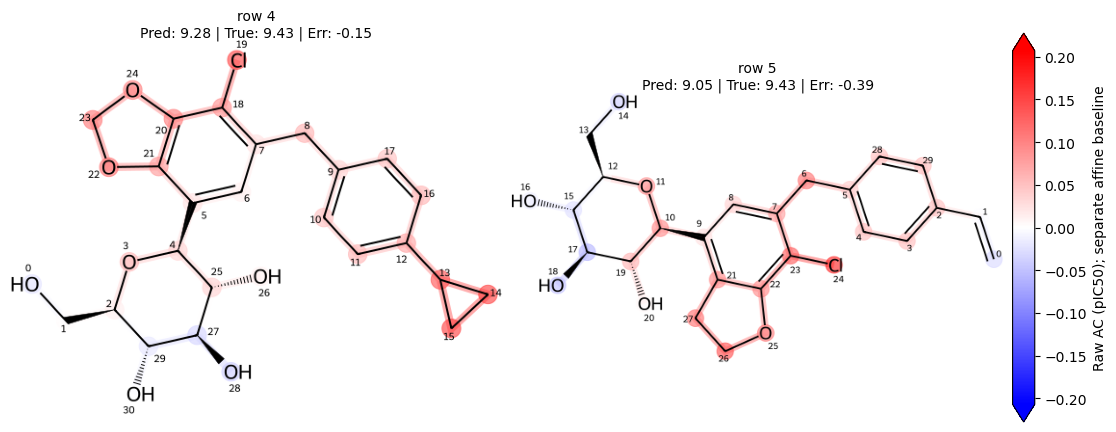

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,4,,validation,OC[C@H]1O[C@@H](c2cc(Cc3ccc(C4CC4)cc3)c(Cl)c3c...,9.434153,9.283989,-0.150164,7.582076,1.701913,0.0,0,0.0
1,5,,validation,C=Cc1ccc(Cc2cc([C@@H]3O[C@H](CO)[C@@H](O)[C@H]...,9.431798,9.045755,-0.386043,7.582076,1.463679,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,4,0,O,-0.021499,0.021499
1,molecule,4,1,C,0.002634,0.002634
2,molecule,4,2,C,0.013780,0.013780
3,molecule,4,3,O,0.057066,0.057066
4,molecule,4,4,C,0.034928,0.034928
...,...,...,...,...,...,...
56,molecule,5,25,O,0.105476,0.105476
57,molecule,5,26,C,0.142182,0.142182
58,molecule,5,27,C,0.114079,0.114079
59,molecule,5,28,C,0.054197,0.054197


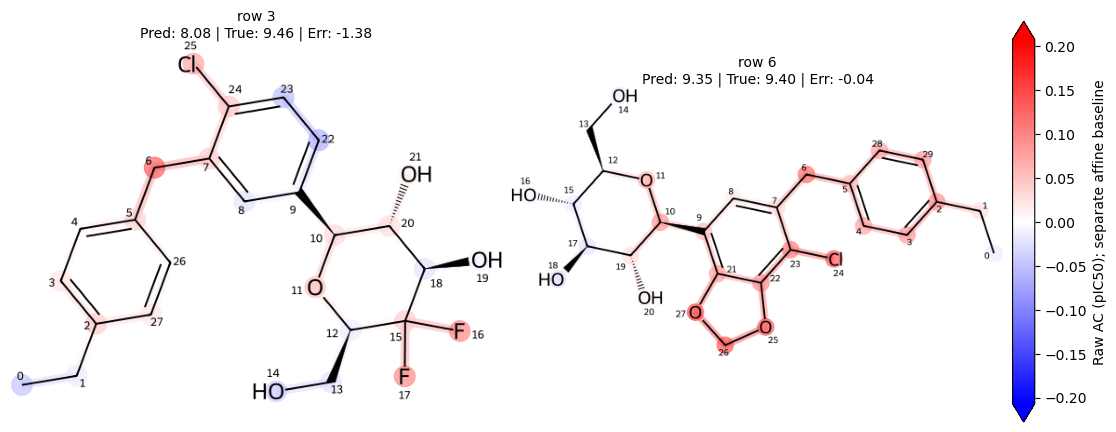

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,3,,validation,CCc1ccc(Cc2cc([C@@H]3O[C@H](CO)C(F)(F)[C@H](O)...,9.455932,8.079090,-1.376842,7.591695,0.487396,0.0,0,0.0
1,6,,validation,CCc1ccc(Cc2cc([C@@H]3O[C@H](CO)[C@@H](O)[C@H](...,9.395774,9.351532,-0.044242,7.591695,1.759837,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,3,0,C,-0.054945,0.054945
1,molecule,3,1,C,-0.018651,0.018651
2,molecule,3,2,C,0.044278,0.044278
3,molecule,3,3,C,0.021845,0.021845
4,molecule,3,4,C,0.001443,0.001443
5,molecule,3,5,C,0.039502,0.039502
6,molecule,3,6,C,0.144353,0.144353
7,molecule,3,7,C,0.044832,0.044832
8,molecule,3,8,C,-0.024980,0.024980
9,molecule,3,9,C,-0.005298,0.005298


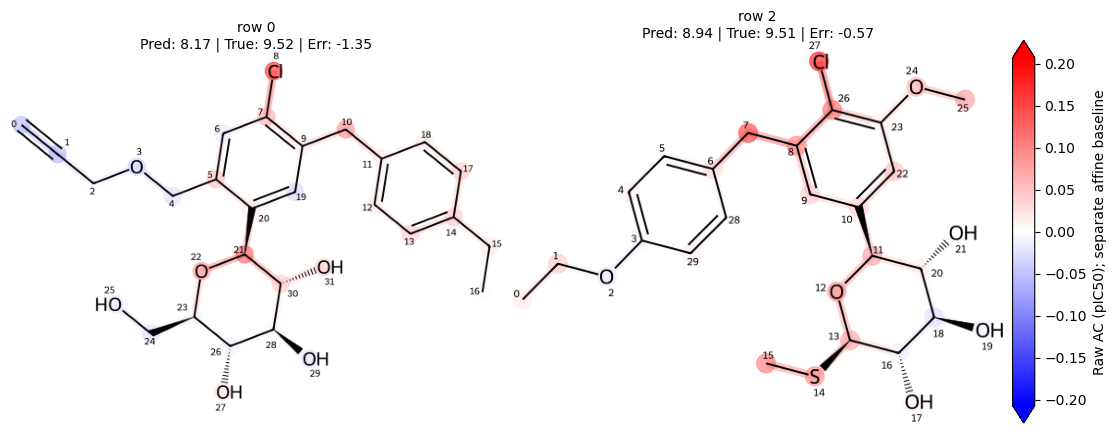

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,0,,validation,C#CCOCc1cc(Cl)c(Cc2ccc(CC)cc2)cc1[C@@H]1O[C@H]...,9.522879,8.172333,-1.350546,7.573209,0.599123,0.0,0,0.0
1,2,,validation,CCOc1ccc(Cc2cc([C@@H]3O[C@H](SC)[C@@H](O)[C@H]...,9.511449,8.936842,-0.574607,7.573209,1.363633,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,0,0,C,-0.056479,0.056479
1,molecule,0,1,C,-0.061982,0.061982
2,molecule,0,2,C,0.000782,0.000782
3,molecule,0,3,O,-0.037464,0.037464
4,molecule,0,4,C,-0.025300,0.025300
...,...,...,...,...,...,...
57,molecule,2,25,C,0.081000,0.081000
58,molecule,2,26,C,0.120932,0.120932
59,molecule,2,27,Cl,0.190424,0.190424
60,molecule,2,28,C,-0.001585,0.001585


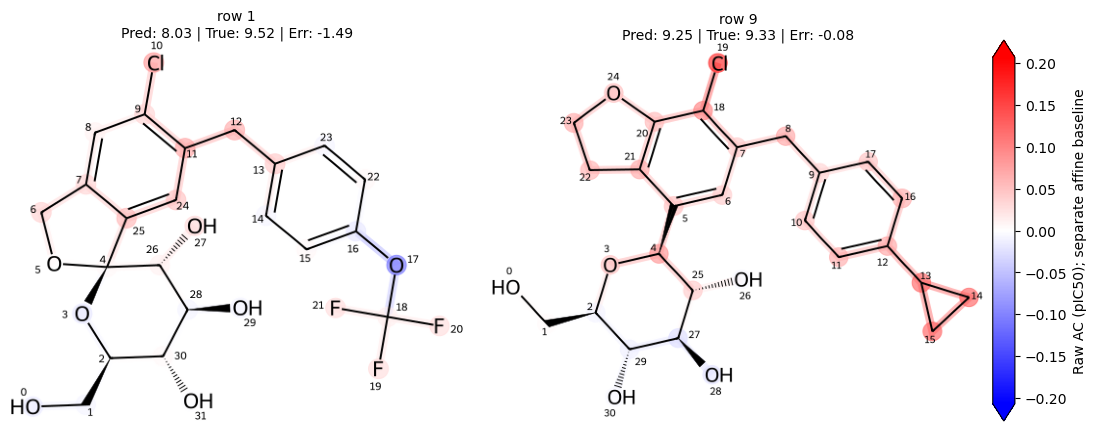

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,1,,validation,OC[C@H]1O[C@]2(OCc3cc(Cl)c(Cc4ccc(OC(F)(F)F)cc...,9.522879,8.031665,-1.491214,7.579294,0.452370,0.0,0,0.0
1,9,,validation,OC[C@H]1O[C@@H](c2cc(Cc3ccc(C4CC4)cc3)c(Cl)c3c...,9.334419,9.249556,-0.084864,7.579294,1.670261,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,1,0,O,-0.016674,0.016674
1,molecule,1,1,C,-0.008626,0.008626
2,molecule,1,2,C,-0.000526,0.000526
3,molecule,1,3,O,-0.020581,0.020581
4,molecule,1,4,C,0.005623,0.005623
...,...,...,...,...,...,...
58,molecule,9,26,O,-0.006734,0.006734
59,molecule,9,27,C,-0.028993,0.028993
60,molecule,9,28,O,-0.023028,0.023028
61,molecule,9,29,C,-0.014323,0.014323


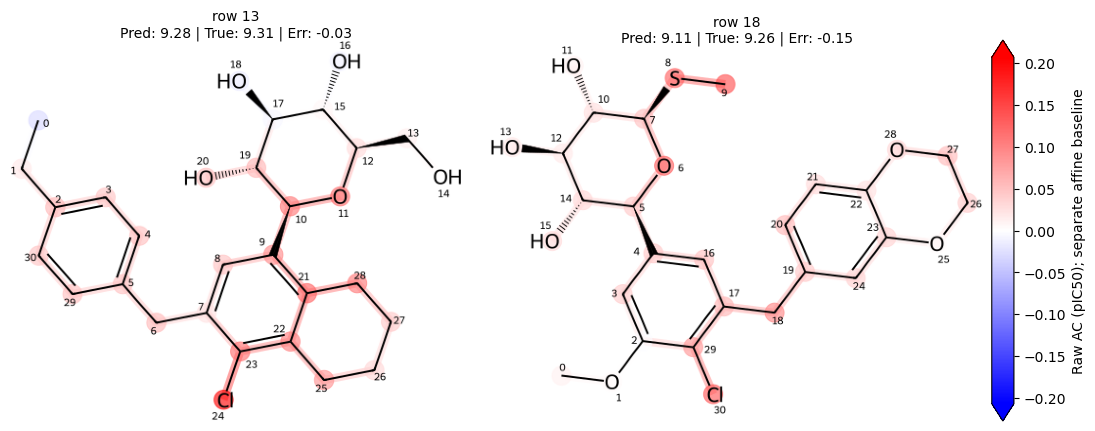

,source_row_index,profile_label,split,smiles,target_raw,prediction_raw,error_raw,affine_baseline_raw,raw_contribution_sum,additivity_residual_raw,color_saturated_atom_count,color_saturated_atom_fraction
0,13,,validation,CCc1ccc(Cc2cc([C@@H]3O[C@H](CO)[C@@H](O)[C@H](...,9.309804,9.277588,-0.032216,7.572822,1.704766,0.0,0,0.0
1,18,,validation,COc1cc([C@@H]2O[C@H](SC)[C@@H](O)[C@H](O)[C@H]...,9.258848,9.109676,-0.149172,7.572822,1.536854,0.0,0,0.0


,side,source_row_index,atom_index,element,raw_contribution,absolute_raw_contribution
0,molecule,13,0,C,-0.031415,0.031415
1,molecule,13,1,C,0.019108,0.019108
2,molecule,13,2,C,0.057948,0.057948
3,molecule,13,3,C,0.048166,0.048166
4,molecule,13,4,C,0.052420,0.052420
...,...,...,...,...,...,...
57,molecule,18,26,C,0.041552,0.041552
58,molecule,18,27,C,0.056240,0.056240
59,molecule,18,28,O,0.033966,0.033966
60,molecule,18,29,C,0.087202,0.087202


In [16]:
from xai_chem.plotting import plot_atom_contribution_grid
# One raw scale covers every displayed molecule across the configured folds.
selected_by_fold = {fold: result.predictions.query("split == 'validation'").head(2)
                    for fold, result in completed.items()}
map_limit = max(float(result.atom_contributions.loc[
    result.atom_contributions.source_row_index.isin(selected_by_fold[fold].source_row_index),
    "atom_contribution_raw"].abs().max()) for fold, result in completed.items())
print({"raw_ac_limit": map_limit, "scale_scope": "displayed molecules across configured folds",
       "condition": condition})
for fold, result in completed.items():
    selected = selected_by_fold[fold]
    figure, molecule_audit, atom_audit = plot_atom_contribution_grid(
        result, source_rows=selected.source_row_index.tolist(),
        symmetric_limit=map_limit, draw_atom_indices=True,
        contribution_label="Raw AC (pIC50); separate affine baseline",
    )
    figure_path = run_root / "vis" / f"{condition}_fold_{fold}_raw_ac.png"
    save_publication_figure(figure, figure_path)
    molecule_audit.to_csv(figure_path.with_suffix(".molecules.csv"), index=False)
    atom_audit.to_csv(figure_path.with_suffix(".atoms.csv"), index=False)
    display(figure); plt.close(figure)
    display(molecule_audit)
    display(atom_audit)


One symmetric raw AC scale covers the displayed validation molecules across all configured folds.
Its numeric limit is printed and saved in the molecule audits. Separate R/U runs can have different
limits, so compare their numerical AC tables rather than colour intensity unless the same limit
is explicitly used. Raw values are neither centred nor standardized. The affine baseline is
separate; neither the map nor in-sample Ridge fidelity establishes causal atomic effects.
